## delete everything the setup created colab

In [ ]:
import os
import shutil
from pathlib import Path

BASE_DIR = Path("/content")

# Never touch a mounted Google Drive: deleting it removes your real Drive files.
KEEP = {"drive"}

# Leave the working directory first, since /content/notebooks gets deleted.
os.chdir(BASE_DIR)

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

## this to upload data to colab and install requerments colab

In [ ]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

BASE_DIR = Path("/content")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            # Handles standard package specs and extras, such as
            # package>=1.0 and package[extra]>=1.0.
            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /content/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()

## delete everything the setup created kaggle

In [3]:
import os
import shutil
from pathlib import Path

# Kaggle: /kaggle/working is the only persistent, writable output dir.
# /kaggle/input is read-only (datasets/models), so it is never touched.
BASE_DIR = Path("/kaggle/working")

# Names to keep (add e.g. "best_model.keras" if you want to preserve outputs)
KEEP = set()

# Leave the directory first, in case the cwd is a folder about to be deleted.
os.chdir(BASE_DIR)

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

Cleanup complete.


## this to upload data to colab and install requerments kaggle

In [ ]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

# Kaggle: /kaggle/working is the only writable, persistent output dir.
BASE_DIR = Path("/kaggle/working")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /kaggle/working/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()
****#%% md
## check if all data are images

In [5]:
import os

image_extensions = {".jpg", ".jpeg", ".png"}
classes = ["glioma", "meningioma", "notumor", "pituitary"]

non_image = []
for c in classes:
    folder_path = os.path.join(RAW_DIR, c)
    for f in os.listdir(folder_path):
        full = os.path.join(folder_path, f)
        if os.path.isfile(full) and os.path.splitext(f)[1].lower() not in image_extensions:
            non_image.append(full)

print(len(non_image))

0


## import libraries and functions

In [6]:
import os
import sys

# run from the project root so "src" and "data/" paths resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay



from src.pipeline import load_dataset_cached, get_datasets
from src.balance import class_distribution

RAW_DIR = os.path.join("data", "raw")
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1792161699.990298     114 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792161699.994174     114 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 2. Load Dataset
OpenCV decode + resize once, then reuse the `.npz` cache.

In [7]:
X, y = load_dataset_cached(RAW_DIR, CLASSES, target_size=IMG_SIZE, seed=SEED)
print(X.shape, X.dtype, y.shape, y.dtype)

Successfully loaded: 1621 images
Skipped: 0 files
Successfully loaded: 1645 images
Skipped: 0 files
Successfully loaded: 2000 images
Skipped: 0 files
Successfully loaded: 1757 images
Skipped: 0 files
(7023, 224, 224, 3) uint8 (7023,) int64


## 3. Class Balance Analysis


Class distribution (full dataset)
  glioma         1621   23.1%  ################################
  meningioma     1645   23.4%  ################################
  notumor        2000   28.5%  ########################################
  pituitary      1757   25.0%  ###################################
  imbalance ratio (max/min) = 1.23 -> balanced enough: no rebalancing needed


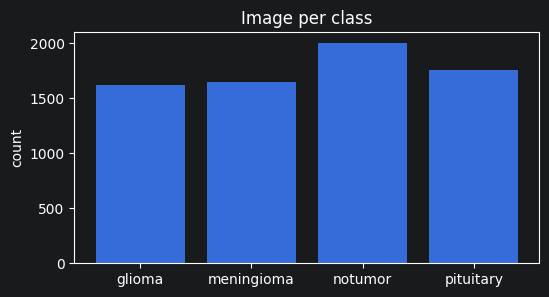

In [8]:
counts = class_distribution(y, CLASSES, "(full dataset)")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts)
plt.title("Image per class")
plt.ylabel("count")
plt.show()

## 4. Build tf.data Pipelines
Stratified train/val split + rebalancing strategy (`auto`, `none`, `class_weight`, `augment`).

In [9]:
train_ds, val_ds, class_weight = get_datasets(
    RAW_DIR, CLASSES,
    batch_size=BATCH_SIZE,
    target_size=IMG_SIZE,
    seed=SEED,
    strategy="auto"
)


Class distribution (train)
  glioma         1297   23.1%  ################################
  meningioma     1316   23.4%  ################################
  notumor        1600   28.5%  ########################################
  pituitary      1406   25.0%  ###################################
  imbalance ratio (max/min) = 1.23 -> balanced enough: no rebalancing needed

Class distribution (val)
  glioma          324   23.1%  ################################
  meningioma      329   23.4%  ################################
  notumor         400   28.5%  ########################################
  pituitary       351   25.0%  ###################################
  imbalance ratio (max/min) = 1.23 -> balanced enough: no rebalancing needed

Rebalancing strategy: none


## 5. Sanity Check (one batch)

In [10]:
for xb, yb in train_ds.take(1):
    print(xb.shape, xb.dtype, yb.shape)
    print("pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

(32, 224, 224, 3) <dtype: 'float32'> (32,)
pixel range: 0.0 - 1.0


## 6. Visualize Samples

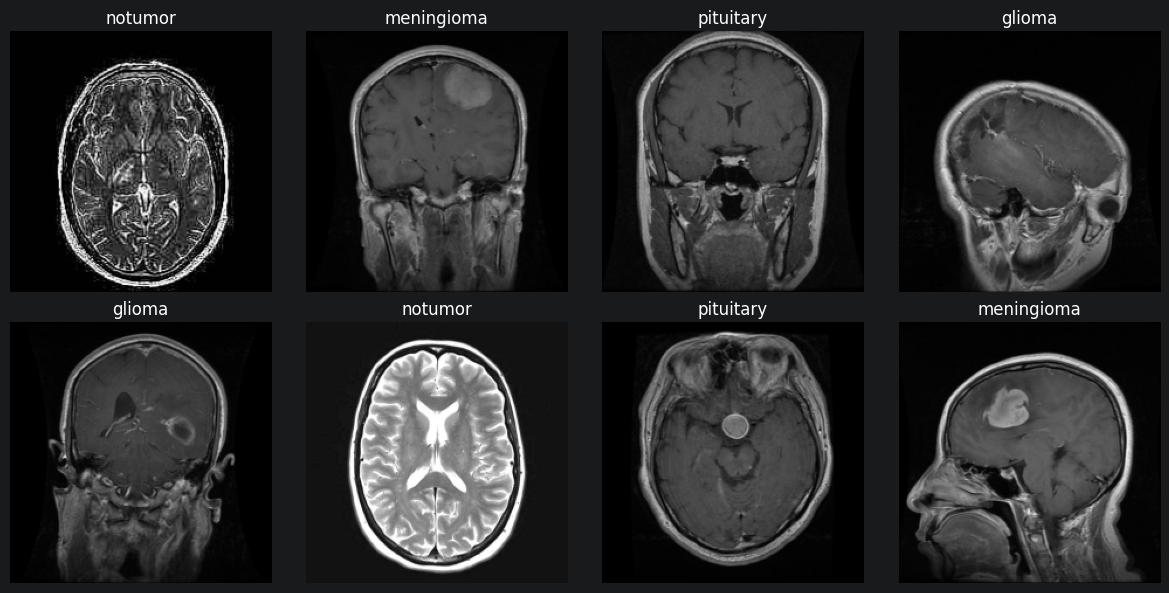

In [11]:
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(xb[i].numpy()[..., ::-1])
    plt.title(CLASSES[int(yb[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build Model

In [12]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    return tf.keras.layers.MaxPooling2D()(x)

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = inputs
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mri_cnn")
model.summary()


Model: "mri_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,884 (1.49 MB)

 Trainable params: 389,924 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

## 8. Compile Model
Integer labels, so `sparse_categorical_crossentropy`.

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## 9. Train

In [15]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    tf.keras.callbacks.ModelCheckpoint("models/best.keras", monitor="val_loss", save_best_only=True),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

Epoch 1/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8494 - loss: 0.4049 - val_accuracy: 0.7123 - val_loss: 0.6866 - learning_rate: 5.0000e-04
Epoch 2/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.8548 - loss: 0.3925 - val_accuracy: 0.4544 - val_loss: 1.4761 - learning_rate: 5.0000e-04
Epoch 3/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.8615 - loss: 0.3702 - val_accuracy: 0.7094 - val_loss: 0.8323 - learning_rate: 5.0000e-04
Epoch 4/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8751 - loss: 0.3421 - val_accuracy: 0.6631 - val_loss: 0.9173 - learning_rate: 2.5000e-04
Epoch 5/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8781 - loss: 0.3278 - val_accuracy: 0.8077 - val_loss: 0.4864 - learning_rate: 2.5000e-04
Epoch 6/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.8829 - loss: 0.3187 - val_accuracy: 0.8462 - val_loss: 0.3747 - learning_rate: 2.5000e-04
Epoch 7/20
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/ste

## 10. Training Curves

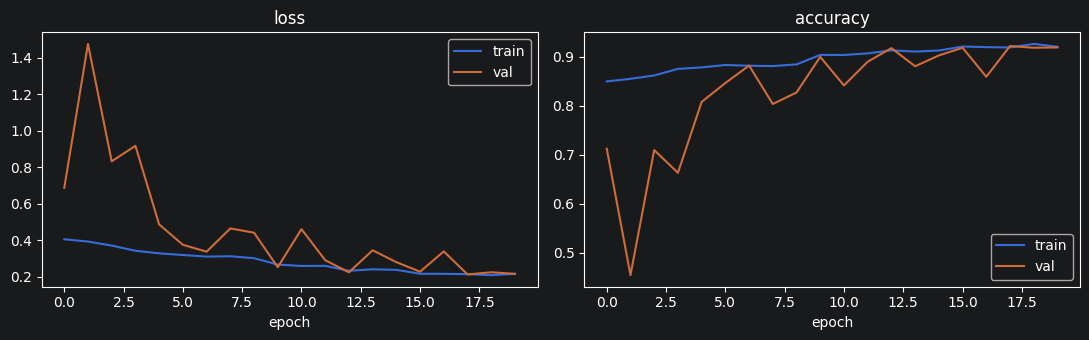

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ("loss", "accuracy")):
    a.plot(history.history[m], label="train")
    a.plot(history.history[f"val_{m}"], label="val")
    a.set_title(m)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()


## 11. Evaluate

In [17]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.4f}")

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9217 - loss: 0.2122
val loss: 0.2122 | val accuracy: 0.9217


## 12. Per-Class Report
val_ds is not shuffled, so predictions and labels line up.

44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step  
              precision    recall  f1-score   support

      glioma      0.957     0.898     0.927       324
  meningioma      0.855     0.824     0.839       329
     notumor      0.975     0.973     0.974       400
   pituitary      0.893     0.977     0.933       351

    accuracy                          0.922      1404
   macro avg      0.920     0.918     0.918      1404
weighted avg      0.922     0.922     0.921      1404



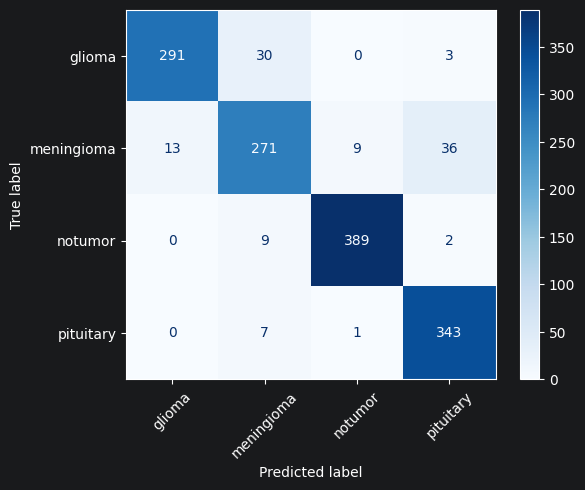

In [18]:
y_true = np.concatenate([yb.numpy() for _, yb in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 13. Save Model

In [19]:
model.save("models/mri_cnn.keras")
print("saved to models/mri_cnn.keras")

saved to models/mri_cnn.keras
